# Linear Regression with Python - Case Study

**Problem Statement**:
You just got a new work contract with an E-commerce company based in New York City. The company sells clothing online but they also have in-store style and clothing advice sessions. Customers come into the store, have sessions/meetings with a personal stylist, then they can go home and order either on a mobile app or website for the clothes they want.

The company is trying to decide whether to focus their efforts on their mobile app experience or their website. They've hired you on contract to help them in figuring it out.

**Objective: Create a model that allows to put in a few features concerning customers attitude and returns back an estimate of the yearly amount spent.**

## Import Data Analysis and Visualization Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

## Data Import

We'll work with the E-commerce Customers csv file from the company. It has Customer info, such as Email, Address, and their Avatar color. Then it also has numerical value columns:

* **Avg. Session Length**: Average length of in-store style advice sessions.
* **Time on App**: Average time spent on App in minutes.
* **Time on Website**: Average time spent on Website in minutes.
* **Length of Membership**: How many years the customer has been a member. 

### TO DO: Load the dataset and inspect its structure

In [5]:
customers = pd.read_csv("Ecommerce Customers.csv")
customers.head()

,Email,Address,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,mstephenson@fernandez.com,"835 Frank Tunnel\nWrightmouth, MI 82180-9605",Violet,34.497268,12.655651,39.577668,4.082621,587.951054
1,hduke@hotmail.com,"4547 Archer Common\nDiazchester, CA 06566-8576",DarkGreen,31.926272,11.109461,37.268959,2.664034,392.204933
2,pallen@yahoo.com,"24645 Valerie Unions Suite 582\nCobbborough, D...",Bisque,33.000915,11.330278,37.110597,4.104543,487.547505
3,riverarebecca@gmail.com,"1414 David Throughway\nPort Jason, OH 22070-1220",SaddleBrown,34.305557,13.717514,36.721283,3.120179,581.852344
4,mstephens@davidson-herman.com,"14023 Rodriguez Passage\nPort Jacobville, PR 3...",MediumAquaMarine,33.330673,12.795189,37.536653,4.446308,599.406092


In [6]:
customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 515 entries, 0 to 514
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Email                 515 non-null    object 
 1   Address               515 non-null    object 
 2   Avatar                515 non-null    object 
 3   Avg. Session Length   515 non-null    float64
 4   Time on App           515 non-null    float64
 5   Time on Website       515 non-null    float64
 6   Length of Membership  515 non-null    float64
 7   Yearly Amount Spent   515 non-null    float64
dtypes: float64(5), object(3)
memory usage: 32.3+ KB


## Exploratory Data Analysis

Before generating models, it is best to take a look at the data we have available. Is there any trend we can recognize from the dataset? Are there any abnormal behaviors?

### TO DO: Display correlations between feature
Focus on 
1. Correlation between [Time on Website] and [Yearly Amount Spent] 
2. Correlation across the entire dataset

Can you recognize some trends?

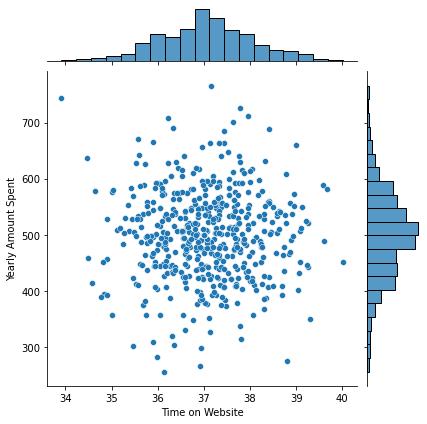

In [8]:
sns.jointplot(x='Time on Website', y='Yearly Amount Spent', data=customers)

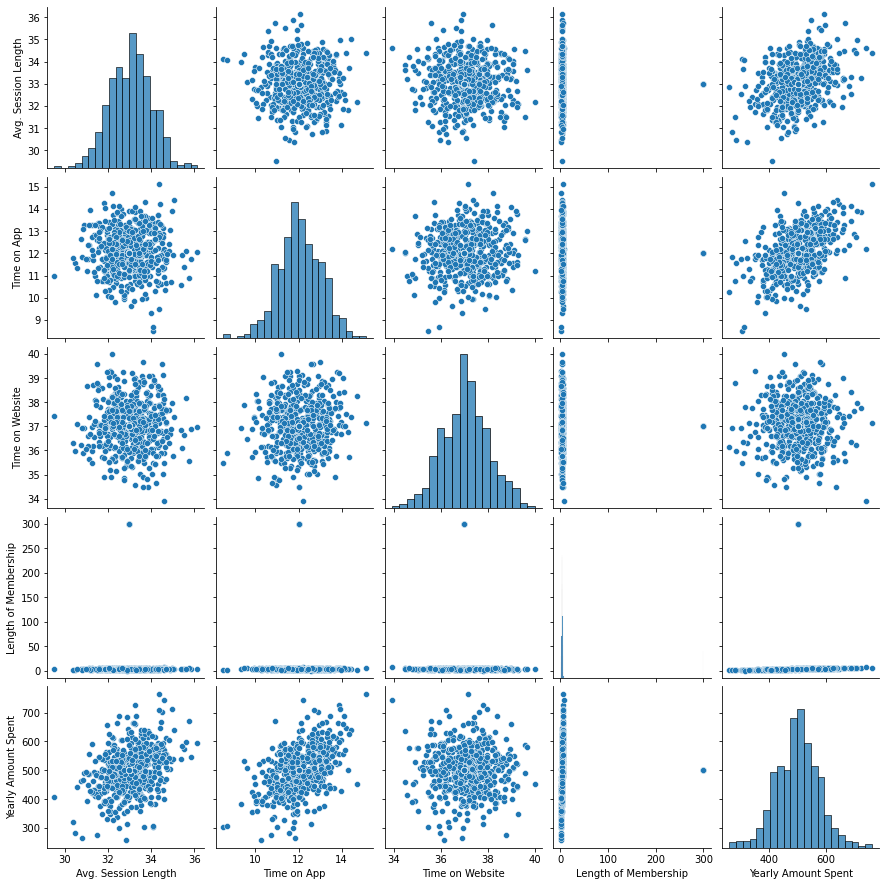

In [9]:
sns.pairplot(customers)

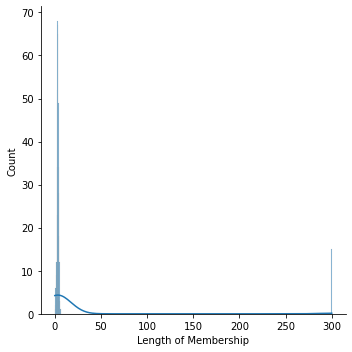

In [10]:
sns.displot(customers['Length of Membership'], kde=True)

The membership length an outlier, which skews the data distribution! It is best to remove it before performing fitting any data, as it may deteriorate the performance of our model!

The IQR (Interquartile Range) method removes outliers by looking at how far values are from the middle of the data.

### TO DO: Remove the outlier(s) and display the new data

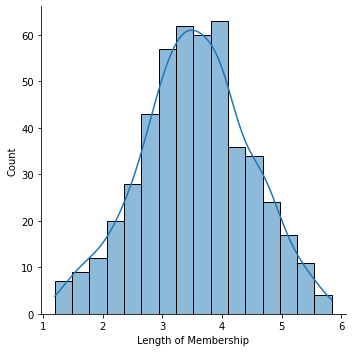

In [12]:
Q1 = customers['Length of Membership'].quantile(0.25)
Q3 = customers['Length of Membership'].quantile(0.75)
IQR = Q3 - Q1

customers = customers[
    (customers['Length of Membership'] >= Q1 - 1.5*IQR) & 
    (customers['Length of Membership'] <= Q3 + 1.5*IQR)
]

sns.displot(customers['Length of Membership'], kde=True)

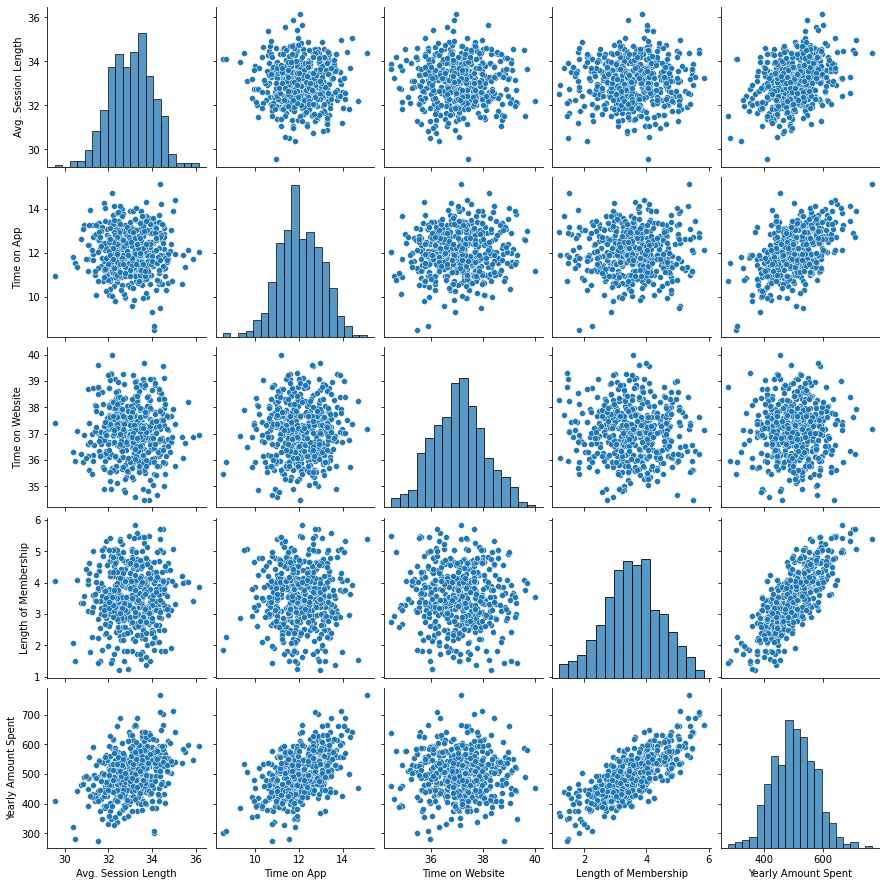

In [13]:
sns.pairplot(customers)

### Evaluating correlation

In pandas, the .corr() method computes pairwise correlation coefficients between the columns of a DataFrame (or between two Series).<br>

By default, it uses Pearson’s correlation, which measures the linear relationship between two variables.<br>

It returns values between -1 and 1:

- +1 → perfect positive linear correlation

- -1 → perfect negative linear correlation

- 0 → no linear correlation<br> <br>

You can also specify other methods: <br>
- Kendall (rank correlation (monotonic, not strictly linear))
- Spearman  (rank correlation (monotonic, based on ranks))

### TO DO: Compute and display the correlation between the dataset feature

In [19]:
# customers.corr()
customers.drop(columns=["Email", "Address", "Avatar"]).corr()

,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
Avg. Session Length,1.000000,-0.021143,-0.019805,0.034527,0.358455
Time on App,-0.021143,1.000000,0.075490,0.011155,0.522239
Time on Website,-0.019805,0.075490,1.000000,-0.041075,0.005465
Length of Membership,0.034527,0.011155,-0.041075,1.000000,0.774775
Yearly Amount Spent,0.358455,0.522239,0.005465,0.774775,1.000000


,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,34.497268,12.655651,39.577668,4.082621,587.951054
1,31.926272,11.109461,37.268959,2.664034,392.204933
2,33.000915,11.330278,37.110597,4.104543,487.547505
3,34.305557,13.717514,36.721283,3.120179,581.852344
4,33.330673,12.795189,37.536653,4.446308,599.406092


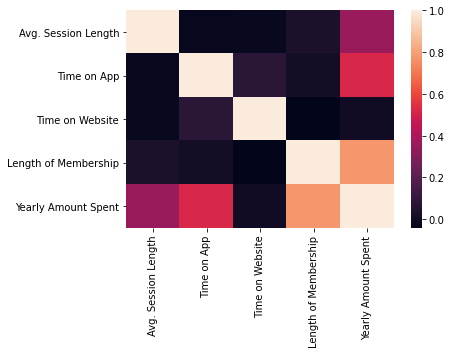

In [23]:
correlation_matrix = customers.drop(columns=["Email", "Address", "Avatar"]).corr()

numerical_columns = customers.select_dtypes(include=['number'])
numerical_columns.head()

# correlation_matrix = numerical_columns.corr()
# sns.heatmap(correlation_matrix)


**Based on these plots, what looks to be the most correlated feature with the Yearly Amount Spent?**

Pearson correlation coefficient between two variables: This coefficient measures the strength and direction of the linear relationship between two continuous variables. <br>

A small p-value (typically less than 0.05) suggests that the correlation is statistically significant, meaning there is evidence to reject the null hypothesis and conclude that a linear relationship likely exists.<br><br>

For non-linear relationships, you can use: Spearman’s rank correlation (ρ)<br>

In [24]:
from scipy.stats import pearsonr 
print('Membership - Membership:', pearsonr(customers['Length of Membership'], customers['Length of Membership']))
print('Amount spent - Membership:', pearsonr(customers['Yearly Amount Spent'], customers['Length of Membership']))
print('Amount spent - App:', pearsonr(customers['Time on App'], customers['Yearly Amount Spent']))
print('Amount spent - Website:', pearsonr(customers['Time on Website'], customers['Yearly Amount Spent']))

Membership - Membership: (0.9999999999999999, 0.0)
Amount spent - Membership: (0.7747745596435982, 1.2474789198800877e-98)
Amount spent - App: (0.5222392824232218, 1.9919112080383583e-35)
Amount spent - Website: (0.005465239164517792, 0.9042468657377846)


# Training a Linear Regression Model

We will need to first split up our data into an X array that contains the numerical features of the customers and a y array with the target variable, in this case the "Yearly Amount Spent" column.

We will toss out all the non-numerical columns because they only have text info that the linear regression model can't use.

In [28]:
X = customers[['Avg. Session Length', 'Time on App', 'Time on Website', 'Length of Membership']]
y = customers['Yearly Amount Spent']

## Train-Test Split  (Supervised learning)

Now let's split the data into a training set and a test set. We will train our model on the training set and then use the test set to evaluate the model.

### TO DO: Perform the train-test split. 

In [29]:
from sklearn.model_selection import train_test_split

# Manual splitting
X_train = X[:int(0.7*len(customers))]

# Function split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)

train_test_split from sklearn shuffles the data by default before splitting. The parameter shuffle=True is set by default, ensuring that the data is randomized before being divided into training and testing sets.
- Avoid Bias: For instance, if the data is ordered by time
- Representative Samples: Shuffling ensures that both the training and test sets contain a good mix of samples
- Handling Class Imbalance: Ensuring that both sets have a balanced distribution of classes

random_state is the seed for reproducibility

## Training the Model
Now that we have divided between training and test data, we need to
1. Define a regression model
2. Train the regression model
3. Evaluate the performance of the regression model

### TO DO: Instantiate and train a linear regression model (call it `lm`)

In [30]:
from sklearn.linear_model import LinearRegression
lm = LinearRegression()
lm.fit(X_train, y_train)

LinearRegression()

In [33]:
lm.__dict__
print('Bias', lm.intercept_)

Bias -1060.481685993544


The linear model `lm` is an object with several attributes and methods (functions). To see the attributes, we can print `lm.__dict__` or `dir(lm)`. 
### TO DO: Display the linear model parameters

In [35]:
print('Bias:', lm.intercept_)
print('Coefficients:', lm.coef_)

Bias: -1060.481685993544
Coefficients: [26.18190492 38.3225182   0.35598941 62.06670986]


## Predicting Test Data and Regression Metrics
Now that we have trained a model, we can evaluate it on the test set. There are many existing evaluation metrics for regression, with some of the most common being:

**Mean Absolute Error** (MAE) is the mean of the absolute value of the errors:

$$\frac 1n\sum_{i=1}^n|y_i-\hat{y}_i|$$

**Mean Squared Error** (MSE) is the mean of the squared errors:

$$\frac 1n\sum_{i=1}^n(y_i-\hat{y}_i)^2$$

**Root Mean Squared Error** (RMSE) is the square root of the mean of the squared errors:

$$\sqrt{\frac 1n\sum_{i=1}^n(y_i-\hat{y}_i)^2}$$

Comparing these metrics:

- **MAE** is the easiest to understand, because it's the average error,  so it represents the error in the same units as the target variable..
- **MSE** is more popular than MAE, because MSE "punishes" larger errors, which could be useful in the real world. Sensitivity to Outliers: MSE is more sensitive to outliers because squaring the error magnifies the impact of larger deviations.
Unit Issue: MSE is not in the same units as the target variable, but in its squared units, which can be less interpretable.
- **RMSE** is even more popular than MSE, because RMSE is interpretable in the "y" units. Sensitivity to Outliers: RMSE, like MSE, is sensitive to outliers due to squaring the errors, but because it takes the square root, the interpretation becomes clearer.

All of these are **loss functions**, because we want to minimize them.

### TO DO: Compute, display, and evaluate the model predictions 

In [37]:
from sklearn import metrics
predictions = lm.predict(X_test)
predictions[0]

518.7651841849272

<function matplotlib.pyplot.show(close=None, block=None)>

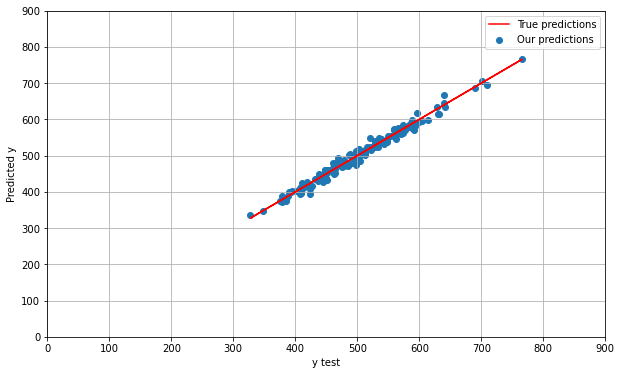

In [39]:
plt.figure(figsize=(10,6))

plt.scatter(y_test, predictions, label='Our predictions')
plt.plot(y_test, y_test, label="True predictions", color='red')

plt.xlabel('y test')
plt.ylabel('Predicted y')
plt.grid()
plt.xlim([0, 900])
plt.ylim([0, 900])
plt.legend()

plt.show

In [40]:
print('MAE:', metrics.mean_absolute_error(y_test, predictions))
print('MSE:', metrics.mean_squared_error(y_test, predictions))
print('RMSE:', np.sqrt(metrics.mean_squared_error(y_test, predictions)))

MAE: 8.441412520715252
MSE: 110.10483346271357
RMSE: 10.493085030757808


## Residuals

You should have obtained a very good model with a good fit. Let's quickly explore the residuals to make sure everything was fine with our data. 

Plot a histogram of the residuals and make sure it looks normally distributed.
If the linear regression model is appropriate and well-fitted, the residuals should follow a normal distribution.

If Residuals Are Not Normally Distributed:
- Non-linearity: The relationship between the variables might not be linear. In that case, consider using polynomial regression or other non-linear models.
- Heteroscedasticity: If the variance of residuals changes across the dataset, this violates the homoscedasticity assumption. You may need to transform the data or use weighted regression.
- Outliers: Extreme values could affect normality. Removing or addressing outliers might improve the model fit.

### TO DO: Display the prediction residuals

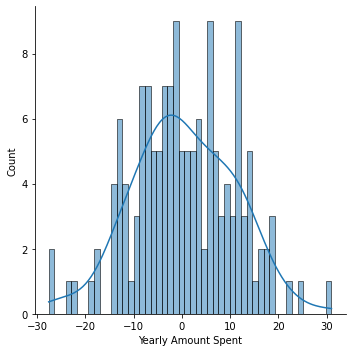

In [41]:
sns.displot( (y_test-predictions), bins=50, kde=True)

## Conclusion
We still want to figure out the answer to the original question, do we focus our effort on mobile app or website development? Or maybe that doesn't even really matter, and Membership Time is what is really important.  Let's see if we can interpret the coefficients to get an idea.


In [42]:
coefficients = pd.DataFrame(lm.coef_,X.columns)
coefficients.columns = ['Coefficient']
coefficients

,Coefficient
Avg. Session Length,26.181905
Time on App,38.322518
Time on Website,0.355989
Length of Membership,62.066710


Interpreting the coefficients:

- Holding all other features fixed, a 1 unit increase in **Avg. Session Length** is associated with an **increase of 26.05 total dollars spent**.
- Holding all other features fixed, a 1 unit increase in **Time on App** is associated with an **increase of 38.72 total dollars spent**.
- Holding all other features fixed, a 1 unit increase in **Time on Website** is associated with an **increase of 0.11 total dollars spent**.
- Holding all other features fixed, a 1 unit increase in **Length of Membership** is associated with an **increase of 61.16 total dollars spent**.

**Do you think the company should focus more on their mobile app or on their website?**


This is tricky, there are two ways to think about this: develop the website to catch up to the performance of the mobile app, or develop the app more since that is what is working better. This sort of answer really depends on the other factors going on at the company, you would probably want to explore the relationship between Length of Membership and the App or the Website before coming to a conclusion!


## Great Job!

Congrats on your contract! The company loved the insights!